# 02 · CoolData value distribution

**Question:** which designs are physically implausible, and which normalization maps the remaining data to [-1, 1]
without being dominated by extremes?

**Answer:**

1. 26 of 5692 designs (0.5 %) break a simple plausibility rule, 3 of them entirely. They are excluded as diverged
   simulations, which removes the implausible extremes of experiment 01.
2. k and ε go on a log10 scale, they span 8 to 10 decades even without the excluded designs.
3. Every channel is normalized by quantiles of the curated designs: q0.001 → -1 and q0.999 → 1, nothing clipped.
   That balances resolution of the bulk against how far the rare peaks reach.

Source: [`experiments/02_cooldata-value-distribution_partial`](../experiments/02_cooldata-value-distribution_partial), a sweep over the
fluid voxels of every design at 1600x320x64: 2048-bin histograms and exact min, max, mean and std per design and
channel.

In [1]:
import os
from pathlib import Path
import sys

from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyvista as pv
import torch

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)  # HOST_CONFIG.cache_dir is `cwd/.cache`, resolved at import
sys.path.insert(0, str(REPO / "experiments"))
import value_distribution as sweep  # noqa: E402, binning, outlier rule and quantile helpers of the sweep

from coolfrog.engine.cooldata import CoolData, CoolMetadata  # noqa: E402
from coolfrog.lib.config import HOST_CONFIG, DataConfig, Grid  # noqa: E402
from coolfrog.lib.datatypes import CHANNELS, Channel, NormalizationStats  # noqa: E402
from coolfrog.lib.experiment import markdown_table  # noqa: E402
from coolfrog.lib.plot import SOLID_COLOR  # noqa: E402

PATH_RESULTS = REPO / "experiments" / "02_cooldata-value-distribution_partial" / "results"
design_stats = pl.read_parquet(PATH_RESULTS / "design_stats.parquet")
histograms = np.load(PATH_RESULTS / "histograms.npz")
excluded = pl.read_csv(PATH_RESULTS / "excluded_designs.csv")
stats = NormalizationStats.load(PATH_RESULTS / "normalization_stats.csv")

design_id, counts = histograms["design_id"], histograms["counts"]  # (D,), (D, C, N_BINS)
is_excluded = np.isin(design_id, excluded["design_id"].to_numpy())
counts_all = counts.sum(0, dtype=np.int64)  # (C, N_BINS)
counts_curated = counts[~is_excluded].sum(0, dtype=np.int64)
CHANNEL_NAMES = [channel.value for channel in CHANNELS]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"{len(design_id)} designs, {is_excluded.sum()} excluded, {(~is_excluded).sum()} curated")

5692 designs, 26 excluded, 5666 curated


## 1. Value ranges

Quantiles over the fluid voxels of all designs, and q0.9999 once the 26 excluded designs are removed. The extremes
sit far out in the tails: T reaches 3862 K at q0.9999 of all voxels, but only 344 K without the excluded designs.

In [2]:
QUANTILES = (1e-4, 0.5, 0.9999)
quantiles_all = sweep.histogram_quantiles(counts_all, QUANTILES)
quantiles_curated = sweep.histogram_quantiles(counts_curated, QUANTILES)
maximum = design_stats.group_by("channel", maintain_order=True).agg(pl.col("max").max())["max"].to_numpy()
value_ranges = pl.DataFrame(
    {
        "channel": CHANNEL_NAMES,
        "q0.0001": quantiles_all[:, 0],
        "median": quantiles_all[:, 1],
        "q0.9999": quantiles_all[:, 2],
        "max": maximum,
        "q0.9999 curated": quantiles_curated[:, 2],
    }
)
display(Markdown(markdown_table(value_ranges, significant_digits=4)))

| channel   | q0.0001   | median     | q0.9999   | max       | q0.9999 curated |
|-----------|-----------|------------|-----------|-----------|-----------------|
| Vx [m/s]  | -13.67    | 2.604      | 47.55     | 533.6     | 43.06           |
| Vy [m/s]  | -13.67    | -7.084e-05 | 13.86     | 1257      | 11.05           |
| Vz [m/s]  | -5.441    | -0.0007801 | 9.061     | 2811      | 8.684           |
| p [Pa]    | -1259     | 0.005794   | 2408      | 5.181e+07 | 2408            |
| T [K]     | 293.1     | 295.6      | 3862      | 4068      | 344             |
| k [m²/s²] | 9.138e-07 | 0.1433     | 266.4     | 9.253e+04 | 69.6            |
| ε [m²/s³] | 4.714e-05 | 9.755      | 5.744e+05 | 1.435e+12 | 2.269e+05       |

## 2. Finding implausible designs

Each curve sorts one statistic per design in descending order: at rank r, r designs exceed it. A spike at the left
means a few designs lie far off the rest.

- Only the max spikes: a few bad voxels in a design
- q0.999 spikes too: a region of at least 0.1 % of the fluid
- The median spikes too: the whole design

Dashed lines: the outlier rule. A design is excluded when any velocity component exceeds 100 m/s or T leaves 250 to
600 K, generous bounds next to inlet speeds of 1 to 7 m/s and bodies of at most 353 K.

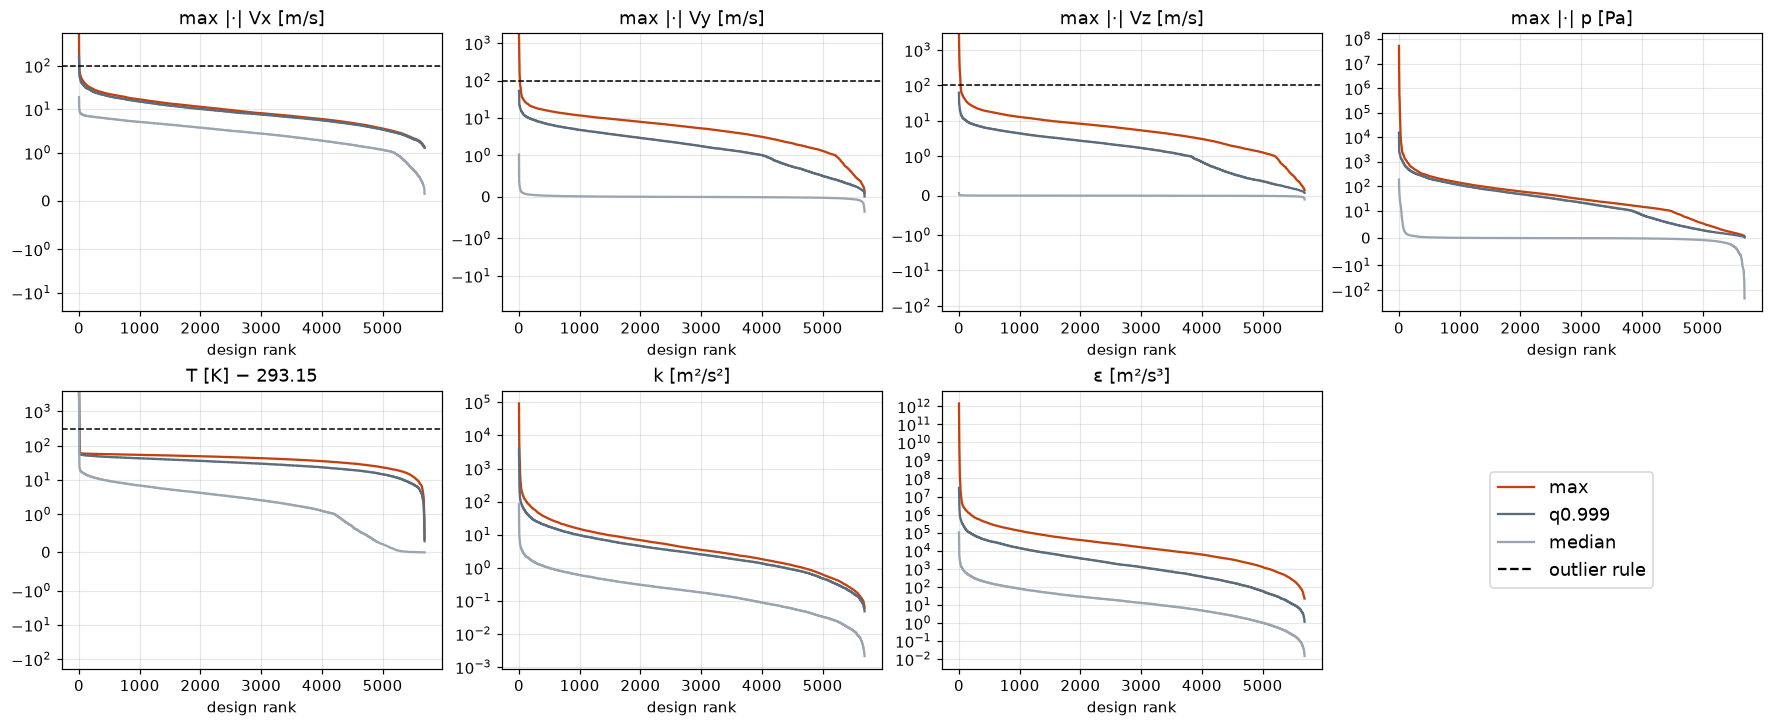

In [3]:
SIGNED_CHANNELS = CHANNELS[:4]  # velocities and p, extremes by max |value|

figure, axes = plt.subplots(2, 4, figsize=(16, 6.5), layout="constrained")
for axis, channel in zip(axes.flat, CHANNELS, strict=False):
    per_design = design_stats.filter(pl.col("channel") == channel.value)
    offset = sweep.BINNING[channel][0]
    extreme = pl.max_horizontal(pl.col("max"), -pl.col("min")) if channel in SIGNED_CHANNELS else pl.col("max")
    for label, column, color in (("max", extreme, "#c2410c"), ("q0.999", pl.col("q0.999"), "#5b6c7d"), ("median", pl.col("q0.5"), "#9aa5b1")):
        values = np.sort(per_design.select(column).to_series().to_numpy())[::-1]
        axis.plot(values - offset, color=color, label=label)
    if channel in CHANNELS[:3]:
        axis.axhline(sweep.MAX_VELOCITY, color="black", linestyle="--", linewidth=1)
    if channel is Channel.TEMPERATURE:
        axis.axhline(sweep.TEMPERATURE_RANGE[1] - offset, color="black", linestyle="--", linewidth=1)
    axis.set_yscale("symlog", linthresh=sweep.BINNING[channel][1] * 100)
    prefix = "max |·| " if channel in SIGNED_CHANNELS else ""
    axis.set_title(prefix + channel.value + (f" − {offset:g}" if offset else ""))
    axis.set_xlabel("design rank")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].axis("off")
axes.flat[-1].legend([*handles, plt.Line2D([], [], color="black", linestyle="--")], [*labels, "outlier rule"], loc="center", fontsize=12)
plt.show()

## 3. Excluded designs

3 designs fail entirely (T median 2234 to 3862 K), the other 23 locally, mostly in a few voxels at the inlet face.
Design 2248 is the exception: a coherent 100 to 164 m/s jet over 8 % of its fluid. Two local failures also run hot
overall, 174805 and 217042 with T medians of 488 and 366 K, above the 353 K the hottest body allows. Design 247781
breaks the rule only at 1600x320x64, its 116 m/s peak is not resolved at 400x80x16.

In [4]:
def share_breaking_rule(design_counts: np.ndarray) -> np.ndarray:
    """(D, C, N_BINS) counts -> (D,) share of fluid voxels whose channel breaks the outlier rule, max over channels."""
    centers = sweep.BIN_CENTERS
    breaks = np.zeros_like(centers, dtype=bool)
    breaks[:3] = np.abs(centers[:3]) > sweep.MAX_VELOCITY
    temperature = CHANNELS.index(Channel.TEMPERATURE)
    breaks[temperature] = (centers[temperature] < sweep.TEMPERATURE_RANGE[0]) | (centers[temperature] > sweep.TEMPERATURE_RANGE[1])
    return ((design_counts * breaks).sum(-1) / design_counts.sum(-1)).max(-1)


temperature_median = design_stats.filter(pl.col("channel") == Channel.TEMPERATURE.value).select("design_id", pl.col("q0.5").alias("T median [K]"))
outliers = (
    pl.DataFrame({"design_id": design_id[is_excluded], "rule-breaking voxels [%]": 100 * share_breaking_rule(counts[is_excluded])})
    .join(excluded, on="design_id")
    .join(temperature_median, on="design_id")
    .with_columns(pl.when(pl.col("rule-breaking voxels [%]") > 50).then(pl.lit("whole design")).otherwise(pl.lit("local")).alias("failure"))
    .sort("rule-breaking voxels [%]", descending=True)
    .select("design_id", "failure", "rule-breaking voxels [%]", "T median [K]", "reason")
)
display(Markdown(markdown_table(outliers, significant_digits=4)))

| design_id | failure      | rule-breaking voxels [%] | T median [K] | reason                                                      |
|-----------|--------------|--------------------------|--------------|-------------------------------------------------------------|
| 243826    | whole design | 99.68                    | 3862         | \|V\| 2811 > 100 m/s, T min 214 < 250 K, T max 4068 > 600 K |
| 128001    | whole design | 99.68                    | 3774         | \|V\| 1682 > 100 m/s, T min 139 < 250 K, T max 4015 > 600 K |
| 245751    | whole design | 97.53                    | 2234         | \|V\| 1255 > 100 m/s, T max 2386 > 600 K                    |
| 2248      | local        | 8.261                    | 311          | \|V\| 164 > 100 m/s                                         |
| 174805    | local        | 0.8623                   | 487.8        | \|V\| 453 > 100 m/s, T max 605 > 600 K                      |
| 217042    | local        | 0.06525                  | 366.1        | \|V\| 483 > 100 m/s                                         |
| 17453     | local        | 0.05655                  | 349.3        | \|V\| 707 > 100 m/s, T max 683 > 600 K                      |
| 205504    | local        | 0.02474                  | 309.6        | \|V\| 165 > 100 m/s                                         |
| 255256    | local        | 0.0236                   | 299.7        | \|V\| 181 > 100 m/s                                         |
| 236352    | local        | 0.02314                  | 307.5        | \|V\| 383 > 100 m/s                                         |
| 173287    | local        | 0.01846                  | 308.8        | \|V\| 260 > 100 m/s                                         |
| 176857    | local        | 0.01825                  | 302          | \|V\| 175 > 100 m/s                                         |
| 34855     | local        | 0.01641                  | 307.8        | \|V\| 931 > 100 m/s, T max 1434 > 600 K                     |
| 252276    | local        | 0.01222                  | 300          | \|V\| 191 > 100 m/s                                         |
| 142521    | local        | 0.01027                  | 297.1        | \|V\| 162 > 100 m/s                                         |
| 161858    | local        | 0.01018                  | 308.4        | \|V\| 199 > 100 m/s                                         |
| 11285     | local        | 0.01001                  | 297.1        | \|V\| 254 > 100 m/s                                         |
| 6897      | local        | 0.009421                 | 299.7        | \|V\| 248 > 100 m/s                                         |
| 20837     | local        | 0.004945                 | 310.6        | \|V\| 391 > 100 m/s                                         |
| 242535    | local        | 0.003122                 | 306.4        | \|V\| 450 > 100 m/s                                         |
| 187314    | local        | 0.002671                 | 300.8        | \|V\| 474 > 100 m/s, T max 674 > 600 K                      |
| 247781    | local        | 0.001422                 | 297.2        | \|V\| 116 > 100 m/s                                         |
| 29839     | local        | 0.000971                 | 305.2        | \|V\| 243 > 100 m/s                                         |
| 20680     | local        | 0.0007429                | 304          | \|V\| 138 > 100 m/s                                         |
| 10901     | local        | 0.0003858                | 296.2        | \|V\| 301 > 100 m/s                                         |
| 6092      | local        | 0.0001168                | 297.8        | \|V\| 908 > 100 m/s, T max 3491 > 600 K                     |

## 4. Where the extremes sit

Each excluded design in 3D: solids translucent grey, coloured voxels break the outlier rule, coloured by speed on one
shared log scale. Inlet at the front left, flow towards the back right. Whole-design failures fill the domain, local
ones sit mostly at the inlet face, 2248 shows its jet. Rendered at 400x80x16, the statistics above come from
1600x320x64.

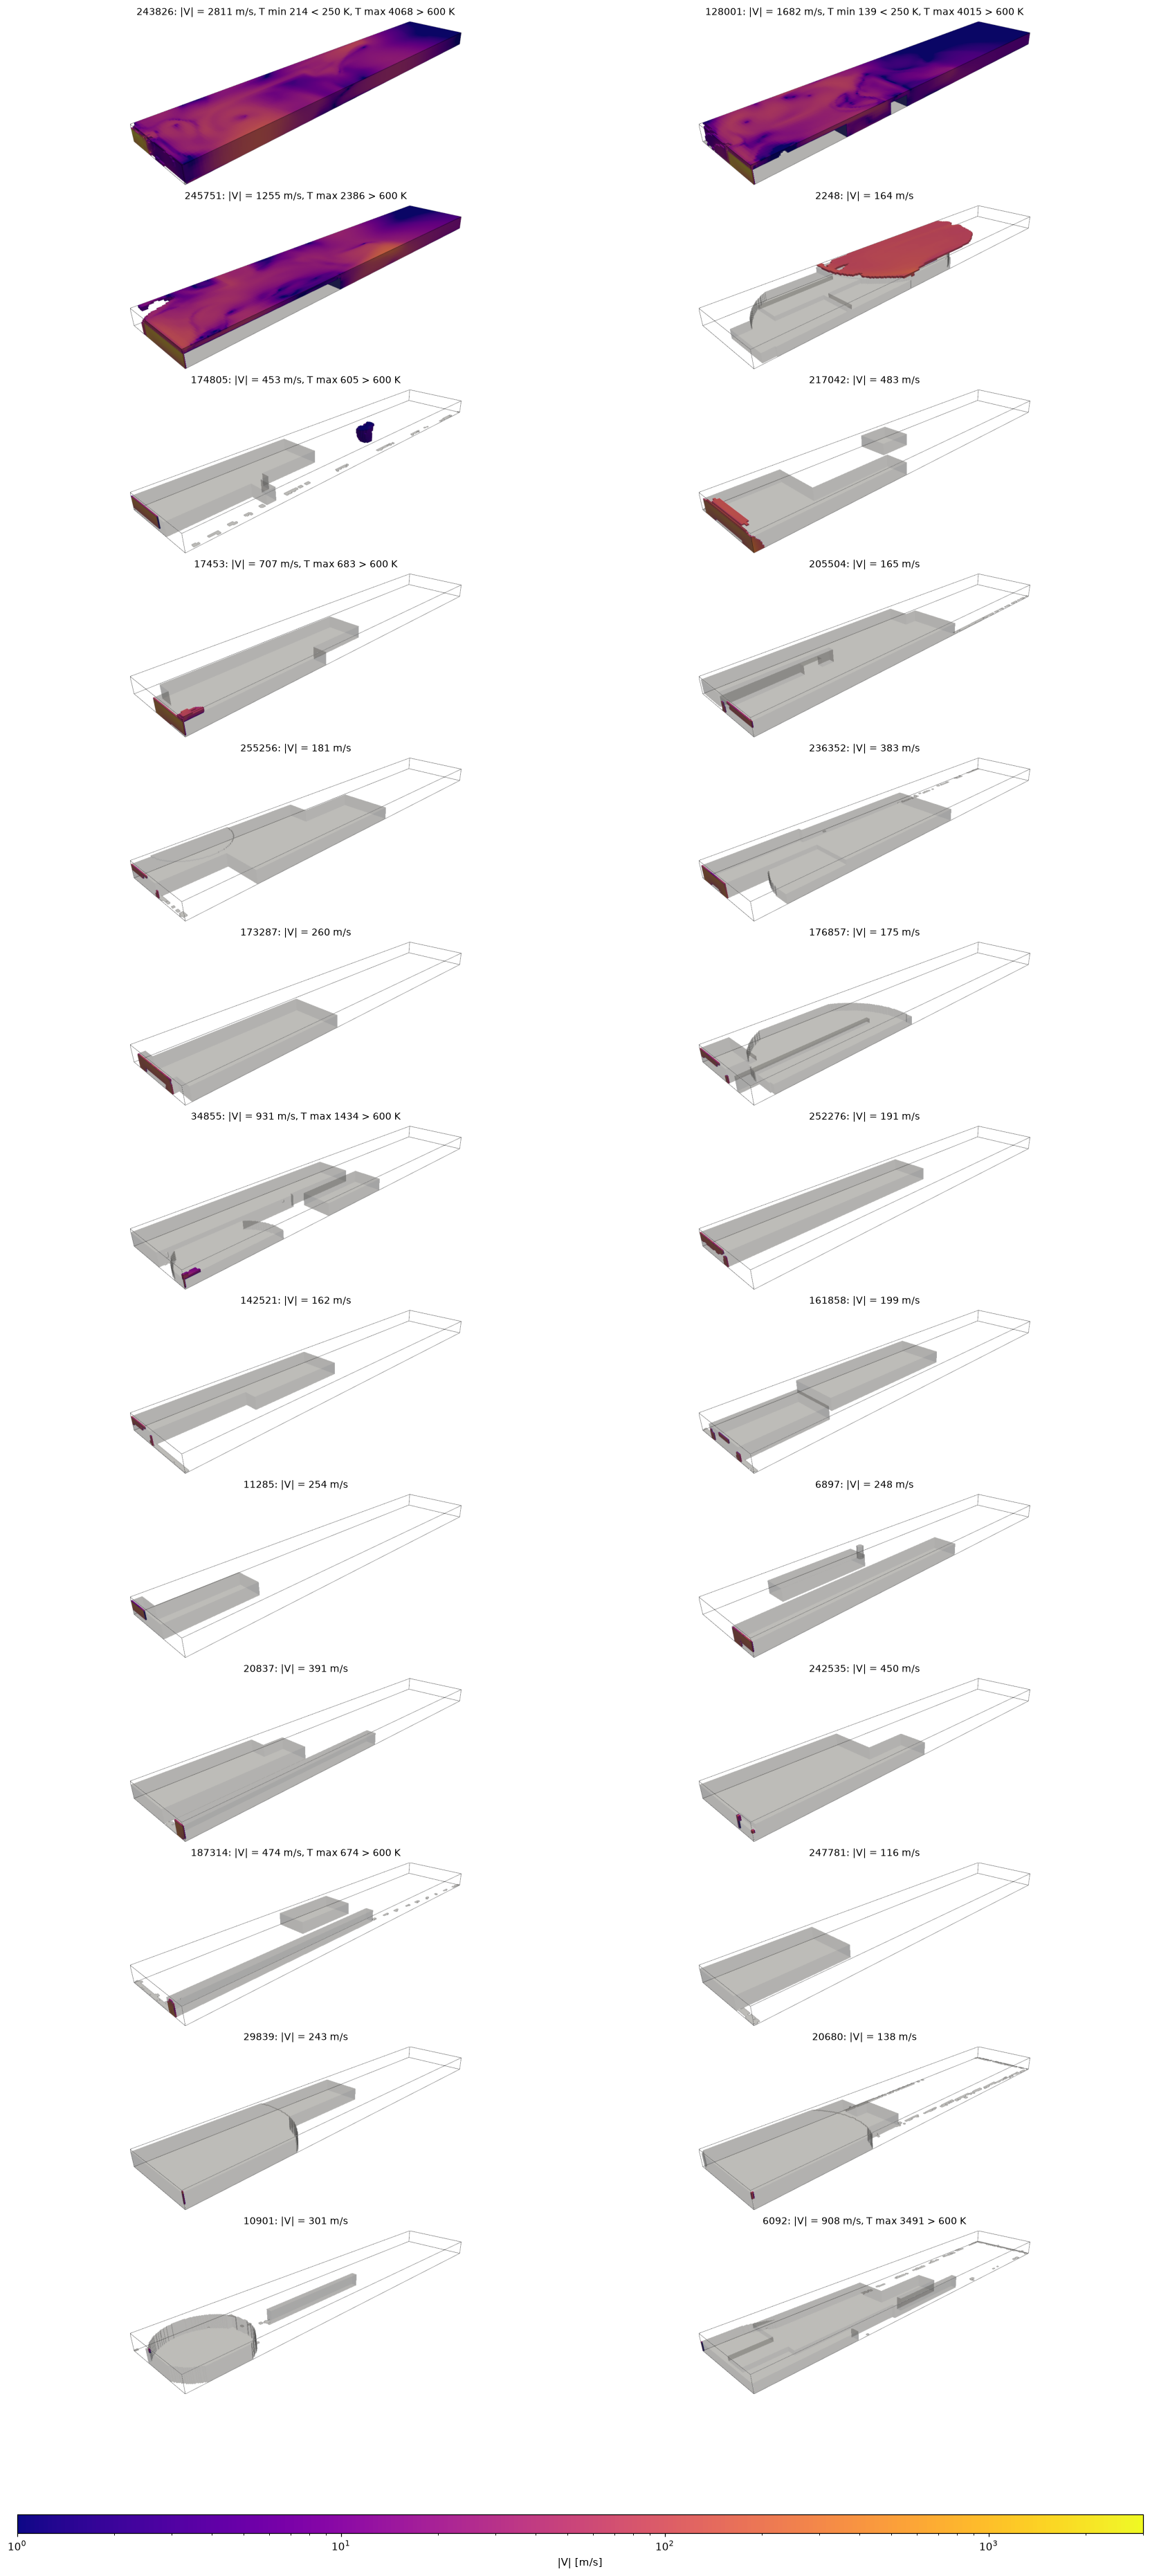

In [5]:
GRID = Grid(latent_scale=1)  # 33M voxels per design at the sweep grid are too heavy to render
SPEED_LIMITS = (1.0, 3000.0)  # m/s, shared colour scale of all renders
metadata = CoolMetadata.load(HOST_CONFIG.n_splits, HOST_CONFIG.idx_split).designs
dataset = CoolData(CoolMetadata(metadata.filter(pl.col("design_id").is_in(outliers["design_id"].to_list()))), DataConfig(grid=GRID))
fields_of = {int(flowfield.design_id): (flowfield.fields.numpy(), flowfield.mask.numpy()) for flowfield in map(dataset.__getitem__, range(len(dataset)))}


def render_rule_breaking_voxels(design: int) -> np.ndarray:
    """Off-screen 3D render of the solids and rule-breaking fluid voxels of `design`, RGB cropped to the content."""
    fields, fluid = fields_of[design]
    speed = np.linalg.norm(fields[:3], axis=0)
    temperature = fields[CHANNELS.index(Channel.TEMPERATURE)]
    breaks_rule = fluid & (
        (np.abs(fields[:3]).max(axis=0) > sweep.MAX_VELOCITY) | (temperature < sweep.TEMPERATURE_RANGE[0]) | (temperature > sweep.TEMPERATURE_RANGE[1])
    )
    image = pv.ImageData(dimensions=GRID.shape, spacing=GRID.spacing)
    for name, volume in (("solid", ~fluid), ("breaks_rule", breaks_rule), ("speed", np.where(fluid, speed, 0.0))):
        image.point_data[name] = volume.astype(np.float32).ravel(order="F")
    plotter = pv.Plotter(off_screen=True, window_size=(1400, 600))
    plotter.add_mesh(image.threshold(0.5, scalars="solid").extract_surface(algorithm="dataset_surface"), color=SOLID_COLOR, opacity=0.3)
    if breaks_rule.any():  # none when the rule only breaks at the sweep grid
        plotter.add_mesh(
            image.threshold(0.5, scalars="breaks_rule"), scalars="speed", cmap="plasma", log_scale=True, clim=SPEED_LIMITS, show_scalar_bar=False
        )
    plotter.add_mesh(image.outline(), color="black")
    plotter.camera_position = [(-0.12, -0.28, 0.22), (0.24, 0.05, 0.0), (0.0, 0.0, 1.0)]
    rgb = plotter.screenshot(return_img=True)
    plotter.close()
    content_rows, content_columns = np.nonzero((rgb < 250).any(axis=-1))
    return rgb[content_rows.min() : content_rows.max() + 1, content_columns.min() : content_columns.max() + 1]


def short_reason(reason: str) -> str:
    """Compact outlier reason for plot titles."""
    return reason.replace("|V| ", "|V| = ").replace(" > 100 m/s", " m/s")


with pv.vtk_verbosity("off"):  # VTK warns about the missing X display, renders off-screen anyway
    renders = {design: render_rule_breaking_voxels(design) for design in outliers["design_id"]}
rows = (outliers.height + 1) // 2
figure, axes = plt.subplots(rows, 2, figsize=(15, 2.6 * rows), layout="constrained")
for axis, (design, reason) in zip(axes.flat, outliers.select("design_id", "reason").iter_rows(), strict=False):
    axis.imshow(renders[design])
    axis.set_title(f"{design}: {short_reason(reason)}", fontsize=9)
for axis in axes.flat:
    axis.axis("off")
figure.colorbar(
    plt.cm.ScalarMappable(norm=LogNorm(*SPEED_LIMITS), cmap="plasma"), ax=axes, orientation="horizontal", fraction=0.01, aspect=60, label="|V| [m/s]"
)
plt.show()

## 5. Distribution per channel

Share of fluid voxels per histogram bin, all designs in grey, curated designs in blue. The x axis is linear near zero
(near 293.15 K for T) and logarithmic beyond, so bulk and tails are both visible. Red lines: q0.001, median and q0.999
of the curated designs. Removing the 26 designs cuts off the far tails, the bulk is unchanged.

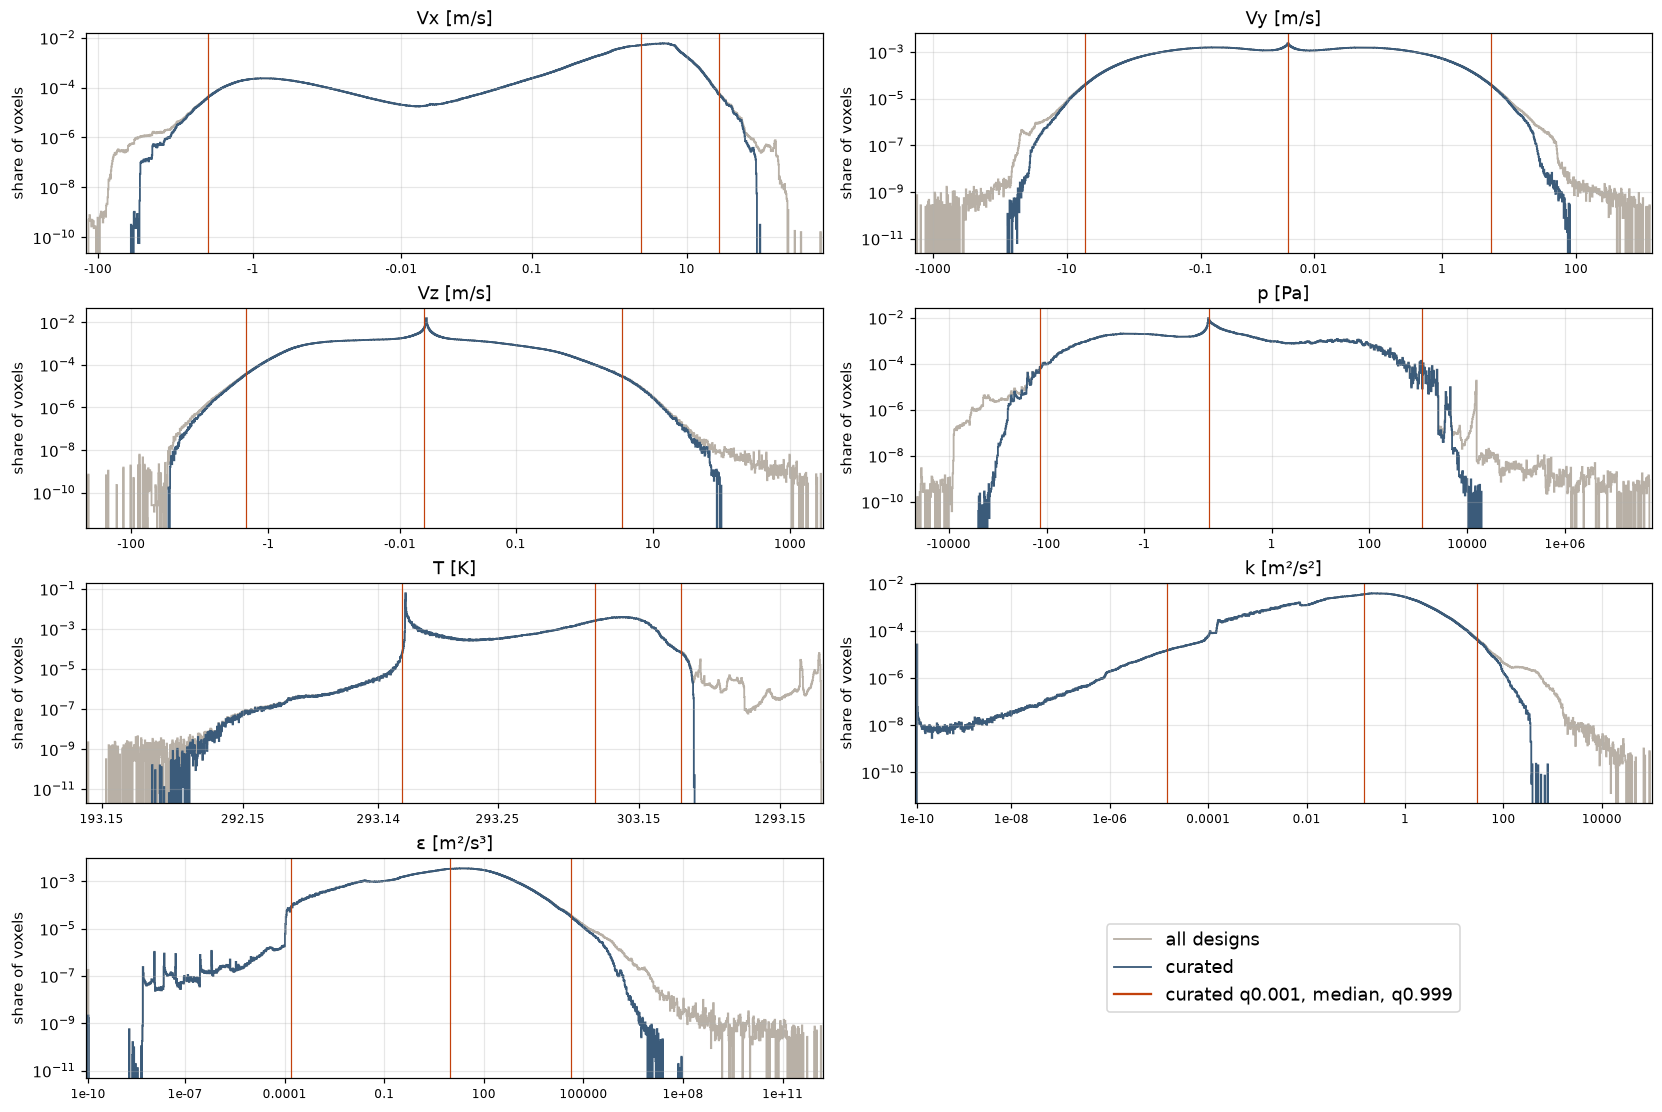

In [6]:
def physical_ticks(channel_index: int, low: float, high: float) -> tuple[np.ndarray, list[str]]:
    """Bin-space positions and labels of offset ± powers of 10 inside [low, high] bin space."""
    offset, scale, *_ = sweep.BINNING[CHANNELS[channel_index]]
    decades = np.arange(np.floor(np.log10(scale)), 15)
    values = np.concatenate([offset - 10.0 ** decades[::-1], [offset], offset + 10.0**decades])
    positions = np.arcsinh((values - offset) / scale)
    inside = (positions >= low) & (positions <= high)
    kept: list[int] = []
    for index in np.flatnonzero(inside):  # at most ~8 ticks, evenly spread in bin space
        if not kept or positions[index] - positions[kept[-1]] >= (high - low) / 8:
            kept.append(index)
    return positions[kept], [f"{value:.6g}" for value in values[kept]]


bin_space_edges = np.arcsinh((histograms["bin_edges"] - sweep.OFFSET.numpy()) / sweep.SCALE.numpy())  # (C, N_BINS + 1)
quantiles_lines = sweep.histogram_quantiles(counts_curated, (1e-3, 0.5, 0.999))

figure, axes = plt.subplots(4, 2, figsize=(15, 10), layout="constrained")
for c, (axis, channel) in enumerate(zip(axes.flat, CHANNELS, strict=False)):
    edges = bin_space_edges[c]
    for channel_counts, color, label in ((counts_all, "#b8b0a6", "all designs"), (counts_curated, "#3b5b7a", "curated")):
        share = channel_counts[c] / channel_counts[c].sum()
        axis.stairs(np.where(share > 0, share, np.nan), edges, color=color, label=label, linewidth=1.2)
    occupied = np.flatnonzero(counts_all[c])
    low, high = edges[max(occupied[0] - 5, 0)], edges[min(occupied[-1] + 6, len(edges) - 1)]
    axis.set_xlim(low, high)
    for value in quantiles_lines[c]:
        axis.axvline(np.arcsinh((value - sweep.OFFSET[c].item()) / sweep.SCALE[c].item()), color="#c2410c", linewidth=0.8)
    axis.set_xticks(*physical_ticks(c, low, high), fontsize=8)
    axis.set_yscale("log")
    axis.set_title(channel.value)
    axis.set_ylabel("share of voxels")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].axis("off")
axes.flat[-1].legend([*handles, plt.Line2D([], [], color="#c2410c")], [*labels, "curated q0.001, median, q0.999"], loc="center", fontsize=12)
plt.show()

## 6. Choosing the normalization

Three candidates on the curated designs, each maps quantile qlow → -1 and qhigh → 1, log10 first for k and ε, nothing
clipped. Narrow quantiles resolve the bulk better but push rare peaks further out, wide ones the opposite.

- **spread**: normalized width of the central 50 % of voxels (q0.25 to q0.75), larger resolves the bulk better
- **peak**: largest |normalized value| of any curated voxel, smaller keeps outliers closer to the training range
- **voxels beyond ±1**: share of curated voxels outside [-1, 1]

In [7]:
def candidate_stats(quantiles: tuple[float, float]) -> NormalizationStats:
    """Curated `quantiles` mapped to [-1, 1], log10 for `sweep.LOG_CHANNELS`, like `sweep.normalization_stats`."""
    low, high = torch.from_numpy(sweep.histogram_quantiles(counts_curated, quantiles)).float().T.reshape(2, -1, 1, 1, 1)
    is_log = torch.tensor([channel in sweep.LOG_CHANNELS for channel in CHANNELS]).view(-1, 1, 1, 1)
    linear = NormalizationStats(low=low, high=high, is_log=is_log, batch_size=[])
    return linear.replace(low=linear.transform(low), high=linear.transform(high))


def normalize(candidate: NormalizationStats, values: np.ndarray) -> np.ndarray:
    """(C, N) physical values -> normalized values under `candidate`."""
    transformed = candidate.transform(torch.from_numpy(values).float().reshape(len(CHANNELS), 1, 1, -1))
    return (2 * (transformed - candidate.low) / (candidate.high - candidate.low) - 1).reshape(values.shape).numpy()


CANDIDATES = ((1e-4, 0.9999), (1e-3, 0.999), (1e-2, 0.99))
curated_stats = design_stats.filter(~pl.col("design_id").is_in(excluded["design_id"].to_list())).group_by("channel", maintain_order=True)
curated_extremes = curated_stats.agg(pl.col("min").min(), pl.col("max").max()).select("min", "max").to_numpy().T  # (2, C)
quartiles = sweep.histogram_quantiles(counts_curated, (0.25, 0.75)).T  # (2, C)
spread_rows, peak_rows = [], []
for quantiles in CANDIDATES:
    candidate = candidate_stats(quantiles)
    label = f"{quantiles[0]:g} / {quantiles[1]:g}"
    spread = normalize(candidate, quartiles[1][:, None]) - normalize(candidate, quartiles[0][:, None])
    peak = np.abs(normalize(candidate, curated_extremes.T)).max(axis=1)
    beyond = (counts_curated * (np.abs(normalize(candidate, sweep.BIN_CENTERS)) > 1)).sum() / counts_curated.sum()
    spread_rows.append({"qlow / qhigh": label, "voxels beyond ±1 [%]": 100 * beyond, **dict(zip(CHANNEL_NAMES, spread[:, 0], strict=True))})
    peak_rows.append({"qlow / qhigh": label, **dict(zip(CHANNEL_NAMES, peak, strict=True))})
display(Markdown("**Spread** of the bulk, larger is better:\n\n" + markdown_table(pl.DataFrame(spread_rows))))
display(Markdown("**Peak** |normalized value|, smaller is better:\n\n" + markdown_table(pl.DataFrame(peak_rows))))

**Spread** of the bulk, larger is better:

| qlow / qhigh    | voxels beyond ±1 [%] | Vx [m/s] | Vy [m/s] | Vz [m/s] | p [Pa]   | T [K] | k [m²/s²] | ε [m²/s³] |
|-----------------|----------------------|----------|----------|----------|----------|-------|-----------|-----------|
| 0.0001 / 0.9999 | 0.0188               | 0.149    | 0.0117   | 0.00634  | 0.000951 | 0.235 | 0.332     | 0.397     |
| 0.001 / 0.999   | 0.194                | 0.254    | 0.0239   | 0.0153   | 0.00197  | 0.302 | 0.416     | 0.456     |
| 0.01 / 0.99     | 1.86                 | 0.472    | 0.0668   | 0.0537   | 0.00957  | 0.577 | 0.571     | 0.561     |

**Peak** |normalized value|, smaller is better:

| qlow / qhigh    | Vx [m/s] | Vy [m/s] | Vz [m/s] | p [Pa] | T [K] | k [m²/s²] | ε [m²/s³] |
|-----------------|----------|----------|----------|--------|-------|-----------|-----------|
| 0.0001 / 0.9999 | 2.8      | 7.36     | 14.3     | 13.3   | 1.75  | 2         | 2.17      |
| 0.001 / 0.999   | 5.18     | 15.1     | 35       | 28.4   | 2.11  | 2.64      | 2.47      |
| 0.01 / 0.99     | 10.2     | 42.1     | 124      | 141    | 4.93  | 3.77      | 2.99      |

**Choice: q0.001 / q0.999.** It roughly doubles the bulk spread of q0.0001 / q0.9999 and keeps every peak at 35 or
below, with 0.2 % of voxels beyond ±1. q0.01 / q0.99 resolves the bulk best but puts Vz and p voxels at 124 and 141:
under an MSE loss, one such voxel outweighs about 10⁴ bulk voxels.

The bulk of Vy, Vz and p stays narrow under every choice (spread ≤ 0.067): most of the fluid is nearly at rest, and a
few jets and pressure peaks set the scale.

Below: the curated voxel density under the chosen normalization. Most voxels fall inside ±1 (red), the tails reach
out to the peaks above.

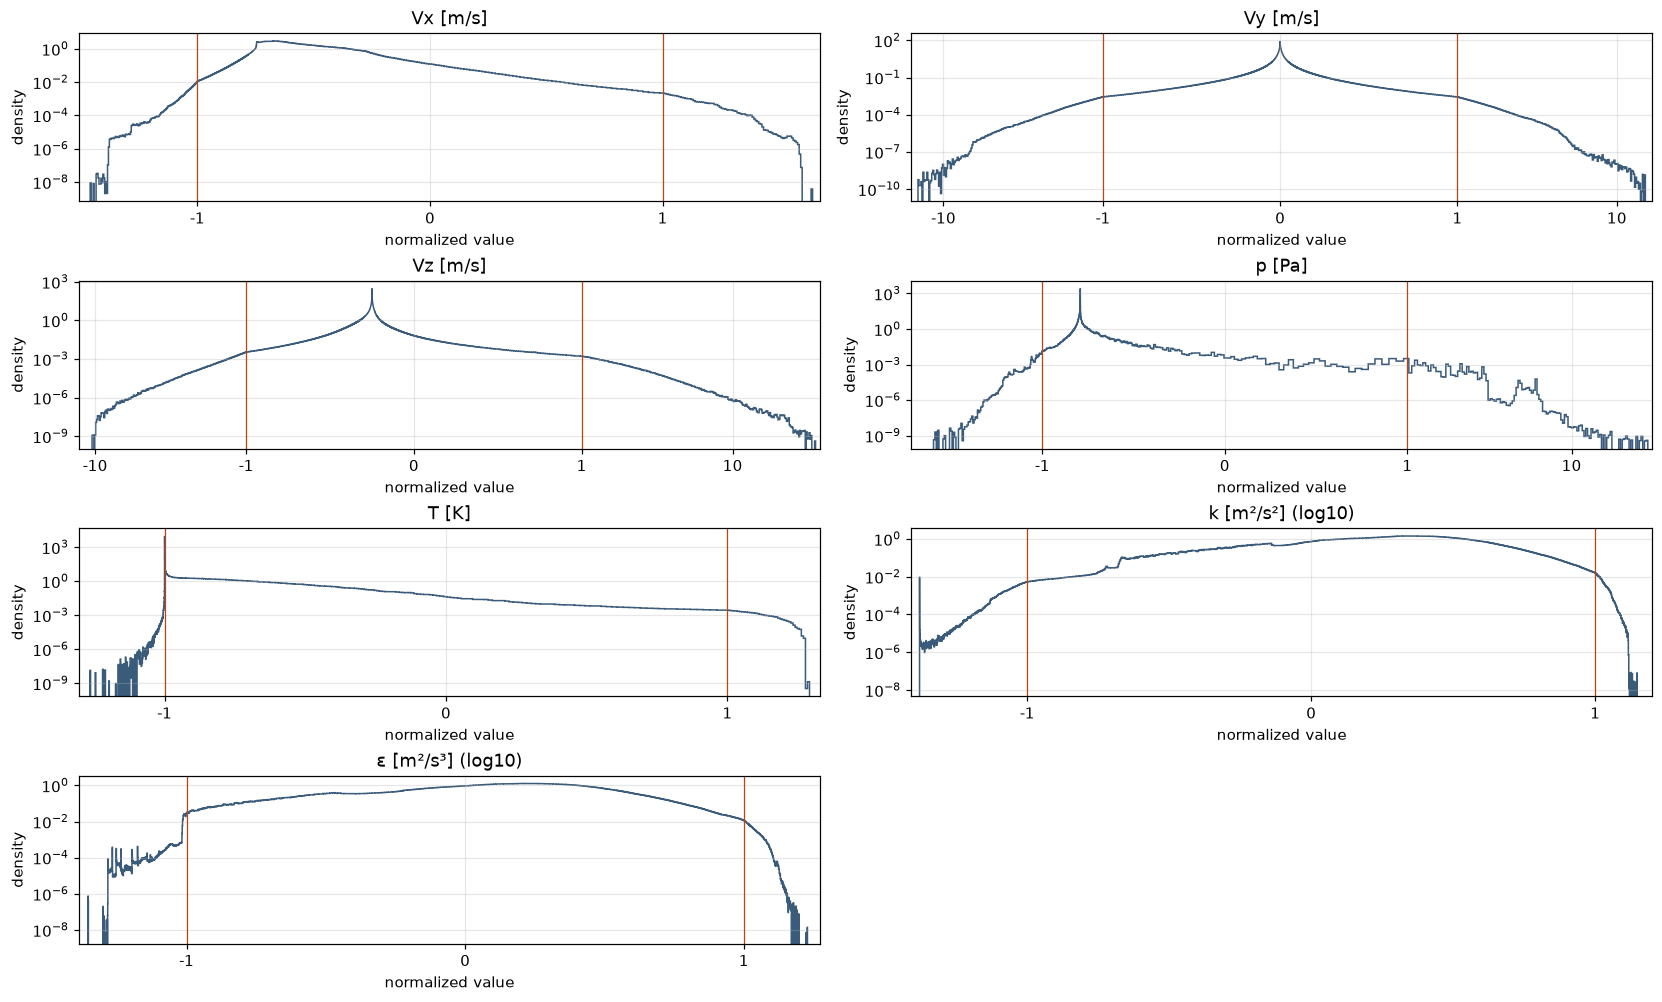

In [8]:
figure, axes = plt.subplots(4, 2, figsize=(15, 9), layout="constrained")
normalized_edges = normalize(stats, histograms["bin_edges"])
for c, (axis, channel) in enumerate(zip(axes.flat, CHANNELS, strict=False)):
    share = counts_curated[c] / counts_curated[c].sum()
    occupied = np.flatnonzero(counts_curated[c])
    edges, share = normalized_edges[c, occupied[0] : occupied[-1] + 2], share[occupied[0] : occupied[-1] + 1]
    density = share / np.diff(edges)  # bins differ in width after normalization
    axis.stairs(np.where(density > 0, density, np.nan), edges, color="#3b5b7a")
    for bound in (-1, 1):
        axis.axvline(bound, color="#c2410c", linewidth=0.8)
    axis.set_xscale("symlog", linthresh=1)
    axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    axis.set_yscale("log")
    axis.set_title(channel.value + (" (log10)" if channel in sweep.LOG_CHANNELS else ""))
    axis.set_xlabel("normalized value")
    axis.set_ylabel("density")
axes.flat[-1].axis("off")
plt.show()

## Conclusion

- Exclude the 26 flagged designs (0.5 % of the data) as physically implausible, likely diverged simulations.
- Put k and ε on a log10 scale, they span 8 to 10 decades between q0.0001 and q0.9999 of the curated designs.
- Normalize every channel with q0.001 → -1 and q0.999 → 1 of the curated designs, without clipping.
- Training uses this normalization and exclusion list, from
  [`results/normalization_stats.csv`](../experiments/02_cooldata-value-distribution_partial/results/normalization_stats.csv)
  and [`results/excluded_designs.csv`](../experiments/02_cooldata-value-distribution_partial/results/excluded_designs.csv).

**Open question:** MSE in log10 space weighs relative errors of k and ε in quiescent regions as much as in turbulent
ones. Keep it, or weight the loss?